In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import find_peaks

from statsmodels.tsa.ar_model import AutoReg, ar_select_order
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

In [2]:
warnings.simplefilter("ignore")
plt.rcParams["figure.figsize"] = (12, 4)
sns.set_style("whitegrid")

H_MAX = 14              # максимальный горизонт = длина тестового блока
N_SEG = 10              # число непересекающихся тестовых блоков
HORIZONS = [1, 7, 14]

In [3]:
from pathlib import Path

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

# Загрузка данных

акции Apple

Возьмем цену закрытия, а не доходности. Нестационарность цены как раз должна отработать компонента I в ARIMA

In [4]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

df_apple = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "anukaggle81/usa-top-900-historic-dataset",
    "Apple.csv",
)
df_apple = df_apple.drop(columns=["Unnamed: 0"])
df_apple["Date"] = pd.to_datetime(df_apple["Date"])
df_apple = df_apple.sort_values("Date").reset_index(drop=True)

apple = df_apple["Close"].tail(1000).to_numpy(dtype=float)
print("Apple:", apple.shape)

Apple: (1000,)


MTA Subway Hourly Ridership (NYC)

Обрезаем ряд 30 октября 2024 (среда). Тестовая зона (25-30 октября, пятница 04:00 - среда 23:00) не содержит праздников. Ноябрь для теста не подходит из-за праздников, которые могли бы попасть в тестовую зону, либо в последние сутки перед ней. В обучающее окно попадает 14 октября (тоже празник), но оставила, на подбор параметров это влияет слабо, так как профиль оценивается по четырем неделям

In [5]:
import urllib.request

url = "https://github.com/xinychen/integers/raw/main/Manhattan-subway/NYC_subway_mob_24.npz"
urllib.request.urlretrieve(url, DATA_DIR / "NYC_subway_mob_24.npz")
tensor = np.load(DATA_DIR / "NYC_subway_mob_24.npz")["arr_0"]
hourly_total = tensor.sum(axis=0)

dates_sub = pd.date_range("2024-01-01", periods=len(hourly_total), freq="h")
END_SUB = "2024-10-30 23:00"
subway = hourly_total[: dates_sub.get_loc(END_SUB) + 1].astype(float)
print("Subway:", subway.shape, "тест с", dates_sub[len(subway) - N_SEG * H_MAX],
      "по", dates_sub[len(subway) - 1])

Subway: (7296,) тест с 2024-10-25 04:00:00 по 2024-10-30 23:00:00


записи ЭКГ 

Берем фрагмент 4800 точек (19 с). Тестовые блоки разнесены с шагом 400 точек (примерно 2.1 удара), поэтому каждый следующий блок сдвинут по фазе кардиоцикла на 20 точек, и 10 блоков покрывают разные участки цикла: изолинию, зубцы P и T, комплекс QRS. Перед каждым блоком модель обучается на 1000 предыдущих точках (где-то 5 ударов).

Сигнал ЭКГ в записи смещен, изолиния находится около 8 единиц, значения всегда положительны. Поэтому MAPE формально определена, но ее величина зависит от этого произвольного смещения. Для ЭКГ дополнительно будем смотреть на MAE

In [6]:
import wfdb

FANTASIA_DIR = DATA_DIR / "fantasia"
if not (FANTASIA_DIR / "f1y01.dat").exists():
    wfdb.dl_database("fantasia", str(FANTASIA_DIR), records=["f1y01"], annotators=["ecg"])
record = wfdb.rdrecord(str(FANTASIA_DIR / "f1y01"))
FS = record.fs
ecg_full = record.p_signal[:, record.sig_name.index("ECG")]

start_idx = 60000
ecg = ecg_full[start_idx:start_idx + 4800].astype(float)
print("ECG:", ecg.shape, "fs =", FS)

ECG: (4800,) fs = 250


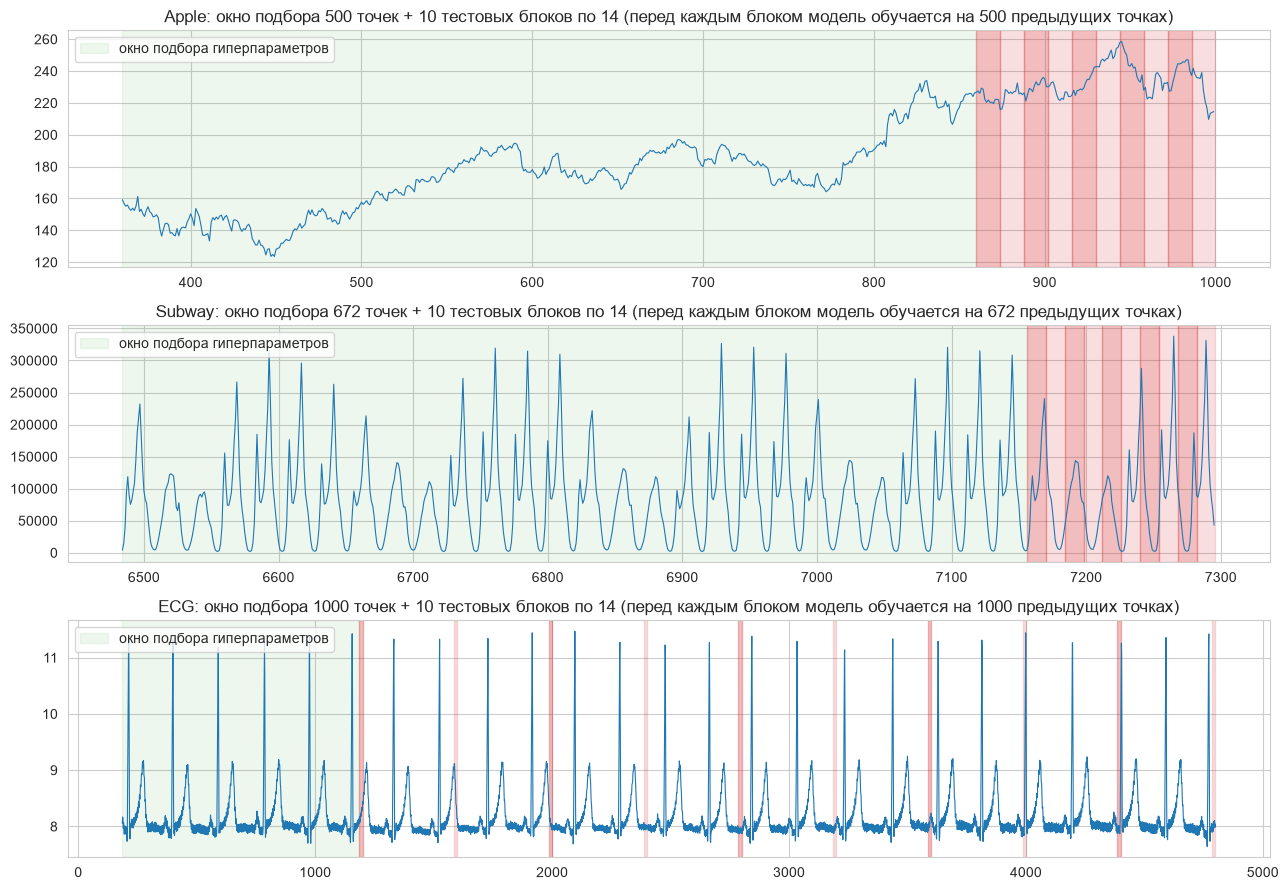

In [7]:
TRAIN_LEN = {"Apple": 500, "Subway": 24 * 7 * 4, "ECG": 1000}
SERIES = {"Apple": apple, "Subway": subway, "ECG": ecg}

GAP = {"Apple": H_MAX, "Subway": H_MAX, "ECG": 400}

def test_origins(n, n_seg=N_SEG, h=H_MAX, gap=H_MAX):
    # gap = h  -> блоки подряд в конце ряда
    # gap > h  -> блоки разнесены, между ними gap - h точек без теста
    assert gap >= h, "блоки не должны пересекаться"
    return [n - h - gap * (n_seg - 1 - k) for k in range(n_seg)]

fig, axes = plt.subplots(3, 1, figsize=(13, 9))
for ax, (name, x) in zip(axes, SERIES.items()):
    origins = test_origins(len(x), gap=GAP[name])
    lo = origins[0] - TRAIN_LEN[name]
    ax.plot(np.arange(lo, len(x)), x[lo:], lw=0.8)
    ax.axvspan(lo, origins[0], color="tab:green", alpha=0.08, label="окно подбора гиперпараметров")
    for k, o in enumerate(origins):
        ax.axvspan(o, o + H_MAX, color="tab:red", alpha=0.15 if k % 2 else 0.3)
    ax.set_title(f"{name}: окно подбора {TRAIN_LEN[name]} точек + 10 тестовых блоков по {H_MAX} "
                 f"(перед каждым блоком модель обучается на {TRAIN_LEN[name]} предыдущих точках)")
    ax.legend(loc="upper left")
plt.tight_layout()

# Вспомогательные функции

* mape - средняя абсолютная процентная ошибка, %. Еще считаем просто mae: у ЭКГ mape зависит от смещения изолинии, а у метро ночные часы с малым пассажиропотоком раздувают проценты, поэтому mae нужна для корректного сравнения моделей

* choose_d - порядок дифференцирования по связке тестов ADF (H0: есть единичный корень) и KPSS (H0: ряд стационарен). Берем минимальное d, при котором ADF отвергает H0, а KPSS - нет

In [8]:
def mape(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    return np.mean(np.abs((y - yhat) / y)) * 100

def mae(y, yhat):
    return np.mean(np.abs(np.asarray(y, float) - np.asarray(yhat, float)))

def choose_d(x, max_d=2, alpha=0.05, seasonal_lag=None):
    # seasonal_lag: если задан, сначала применяется сезонная разность
    z = np.asarray(x, float)
    if seasonal_lag:
        z = z[seasonal_lag:] - z[:-seasonal_lag]
    rows = []
    for d in range(max_d + 1):
        zd = np.diff(z, n=d) if d else z
        adf_p = adfuller(zd, autolag="AIC")[1]
        kpss_p = kpss(zd, regression="c", nlags="auto")[1]
        rows.append({"d": d, "ADF p-value": round(adf_p, 4), "KPSS p-value": round(kpss_p, 4)})
        if adf_p < alpha and kpss_p > alpha:
            return d, pd.DataFrame(rows)
    return max_d, pd.DataFrame(rows)

* grid_sarima - подбор порядков ARIMA/SARIMA

Перебирает все сочетания порядков из диапазонов:

1. p сколько прошлых значений учитывается;
2. q сколько прошлых ошибок учитывается;
3. P, Q то же самое для сезонных лагов (через m шагов);
4. d, D порядки обычного и сезонного дифференцирования. Не перебираются, их заранее определяет choose_d по тестам ADF/KPSS

Лучший вариант выбирается по AIC, который учитывает качество подгонки и штрафует за число параметров

* grid_hw - подбор конфигурации Хольта–Винтерса

Перебираются структурные варианты модели. Каждый элемент configs - словарь, который задает есть ли тренд и затухает ли он, есть ли сезонность (аддитивная или мультипликативная) и какой у нее период

Лучший вариант выбирается по AICc (AIC с поправкой на размер выборки)

In [9]:
def grid_sarima(x, d, p_range, q_range, P_range=(0,), Q_range=(0,), D=0, m=0):
    trend = "c" if (d + D) == 0 else "n"
    rows = []
    for p in p_range:
        for q in q_range:
            for P in P_range:
                for Q in Q_range:
                    try:
                        res = SARIMAX(x, order=(p, d, q),
                                      seasonal_order=(P, D, Q, m) if m else (0, 0, 0, 0),
                                      trend=trend).fit(disp=False)
                        rows.append({"p": p, "d": d, "q": q, "P": P, "D": D, "Q": Q,
                                     "AIC": res.aic, "BIC": res.bic})
                    except Exception as e:
                        pass
    return pd.DataFrame(rows).sort_values("AIC").reset_index(drop=True)

def grid_hw(x, configs, init="estimated"):
    rows = []
    for cfg in configs:
        try:
            res = ExponentialSmoothing(x, initialization_method=init, **cfg).fit()
            rows.append({**cfg, "AICc": res.aicc, "alpha": res.params["smoothing_level"],
                         "beta": res.params.get("smoothing_trend"),
                         "gamma": res.params.get("smoothing_seasonal")})
        except Exception as e:
            pass
    return pd.DataFrame(rows).sort_values("AICc").reset_index(drop=True)

Единый интерфейс - модель получает обучающее окно и конфиг ряда, возвращает прогноз на H_MAX шагов

Базовые (наивные) прогнозы для сравнения:

Naive — для Apple последнее значение (m=1), для ЭКГ копия прошлого удара (m = медианный RR), для метро копия прошлых суток (m=24);

Naive-168 (только метро) — копия прошлой недели. Нужен, чтобы проверить, дает ли Хольт–Винтерс с m=168 что-то сверх простого повтора недельного профиля.

In [10]:
def fc_ar(train, cfg):
    res = AutoReg(train, lags=cfg["ar_lags"], trend="c").fit()
    return res.predict(start=len(train), end=len(train) + H_MAX - 1)

def fc_arima(train, cfg):
    res = SARIMAX(train, order=cfg["order"], seasonal_order=cfg["seasonal_order"],
                  trend=cfg["arima_trend"]).fit(disp=False)
    return res.forecast(H_MAX)

def fc_sarima(train, cfg):
    res = SARIMAX(train, order=cfg["sarima_order"], seasonal_order=cfg["sarima_seasonal"],
                  trend="n").fit(disp=False)
    return res.forecast(H_MAX)

def fc_hw(train, cfg):
    res = ExponentialSmoothing(train, initialization_method=cfg["hw_init"], **cfg["hw"]).fit()
    return res.forecast(H_MAX)

def fc_naive(train, cfg):
    m = cfg["naive_m"]           # m = 1 -> последнее значение, m > 1 -> сезонно-наивный
    return np.array([train[len(train) - m + (i % m)] for i in range(H_MAX)])

def fc_naive_week(train, cfg):
    m = cfg["naive_week_m"]      # как неделю назад
    return np.array([train[len(train) - m + (i % m)] for i in range(H_MAX)])

MODELS = {"AR": fc_ar, "ARIMA": fc_arima, "SARIMA": fc_sarima, "Holt-Winters": fc_hw,
          "Naive": fc_naive, "Naive-168": fc_naive_week}
CFG = {}

# Подбор гиперпараметров

## Apple

In [11]:
name = "Apple"
x = SERIES[name]
o0 = test_origins(len(x), gap=GAP[name])[0]
sel = x[o0 - TRAIN_LEN[name]: o0]

d_apple, tbl = choose_d(sel)
print(f"Выбранный порядок дифференцирования d = {d_apple}")

Выбранный порядок дифференцирования d = 1


In [12]:
tbl

,d,ADF p-value,KPSS p-value
0,0,0.9157,0.01
1,1,0.0000,0.10


d=0: ADF p=0.92, то есть гипотезу о единичном корне отвергнуть нельзя. KPSS p=0.01 отвергает стационарность. Значит, цена нестационарна

d=1: ADF p=0 и KPSS p=0.10, оба теста говорят о стационарности. Значит, d=1

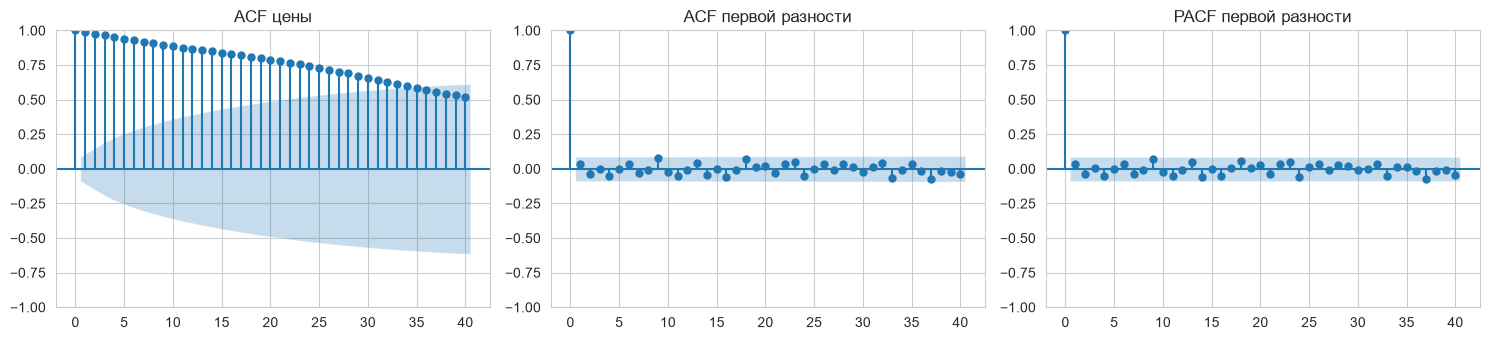

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
plot_acf(sel, lags=40, ax=axes[0], title="ACF цены")
plot_acf(np.diff(sel), lags=40, ax=axes[1], title="ACF первой разности")
plot_pacf(np.diff(sel), lags=40, ax=axes[2], title="PACF первой разности", method="ywm")
plt.tight_layout()

ACF цены затухает медленно и похоже на линейно. Подтверждается нестационарность

В ACF и PACF первой разности все лаги внутри доверительной области. Изменения цены от дня ко дню практически не коррелируют между собой

*AR*

Модель AR строим на самой цене, порядок p выбираем по BIC (ar_select_order, лаги 1…20). BIC штрафует за число параметров сильнее AIC, поэтому реже берет случайные лаги, которые на почти случайном ряде не помогают прогнозу

In [14]:
ar_sel = ar_select_order(sel, maxlag=20, ic="bic", trend="c")
print("Лаги AR по BIC:", ar_sel.ar_lags)

Лаги AR по BIC: [1]


In [15]:
ar_fit = AutoReg(sel, lags=ar_sel.ar_lags, trend="c").fit()
print(ar_fit.params.round(4))

[0.4594 0.9981]


Модель почти совпадает со случайным блужданием, ее прогноз практически равен последнему значению

*ARIMA.* 

d фиксировано тестами, $p, q \in \{0, \dots, 3\}$ перебираем по AIC. Для правильной модели остатки должны быть белым шумом

In [16]:
g = grid_sarima(sel, d=d_apple, p_range=range(4), q_range=range(4))
display(g.head(5))
p, d, q = int(g.loc[0, "p"]), int(g.loc[0, "d"]), int(g.loc[0, "q"])
order_apple = (p, d, q)
res = SARIMAX(sel, order=order_apple, trend="c" if d == 0 else "n").fit(disp=False)
print("ARIMA", order_apple)
print(acorr_ljungbox(res.resid[d:], lags=[10, 20]))

,p,d,q,P,D,Q,AIC,BIC
0,0,1,0,0,0,0,2413.105398,2417.318004
1,0,1,1,0,0,0,2414.259599,2422.684811
2,1,1,0,0,0,0,2414.317031,2422.742244
3,1,1,1,0,0,0,2415.388477,2428.026295
4,0,1,2,0,0,0,2415.642177,2428.279995


ARIMA (0, 1, 0)
      lb_stat  lb_pvalue
10   7.083340   0.717554
20  15.447104   0.750278


По AIC выбрана ARIMA(0,1,0), то есть случайное блуждание, а более сложные варианты хуже менее чем на 2 единицы AIC. Тест Льюнга–Бокса (p > 0.7 на лагах 10 и 20) не отвергает гипотезу о белом шуме в остатках. Ее прогноз равен последнему наблюдаемому значению, то есть совпадает с наивным

*Хольт–Винтерс* 

У цены акции нет сезонности, поэтому сезонная компонента отключена и метод вырождается в метод Хольта. Сравниваем по AICc три варианта: без тренда, аддитивный тренд, затухающий тренд. Коэффициенты альфа и бета подбираются максимизацией правдоподобия

In [17]:
hw_cfgs = [
    dict(trend=None, seasonal=None),
    dict(trend="add", seasonal=None),
    dict(trend="add", damped_trend=True, seasonal=None),
]
g_hw = grid_hw(sel, hw_cfgs)
display(g_hw)
best_hw = {k: v for k, v in g_hw.iloc[0].items() if k in ("trend", "damped_trend", "seasonal", "seasonal_periods")}
best_hw = {k: v for k, v in best_hw.items() if not (isinstance(v, float) and np.isnan(v))}
print("Выбрано:", best_hw)

CFG[name] = dict(ar_lags=ar_sel.ar_lags, order=order_apple, seasonal_order=(0, 0, 0, 0), sarima_order=None,
                 arima_trend="c" if d_apple == 0 else "n",
                 hw=best_hw, hw_init="estimated", naive_m=1)

,trend,seasonal,AICc,alpha,beta,gamma,damped_trend
0,NaN,None,1000.078547,1.0,NaN,NaN,NaN
1,add,None,1002.936386,1.0,0.000000,NaN,NaN
2,add,None,1004.926206,1.0,0.000107,NaN,True


Выбрано: {'seasonal': None}


По AICc выбрано простое экспоненциальное сглаживание без тренда: у вариантов с трендом бета=0, то есть устойчивого направления в цене нет. альфа=1 модель не сглаживает, а целиком доверяет последнему наблюдению

## Метро

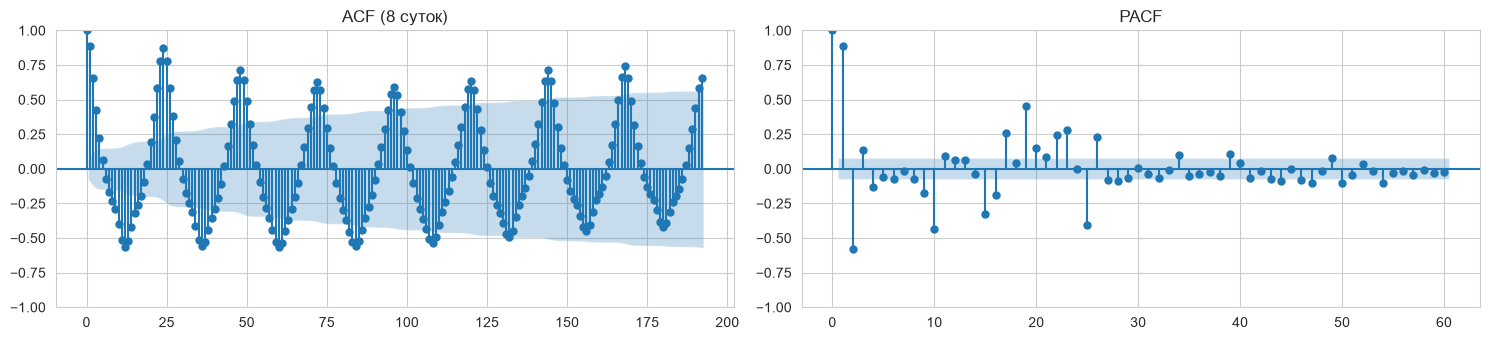

In [18]:
name = "Subway"
x = SERIES[name]
o0 = test_origins(len(x), gap=GAP[name])[0]
sel = x[o0 - TRAIN_LEN[name]: o0]

fig, axes = plt.subplots(1, 2, figsize=(15, 3.5))
plot_acf(sel, lags=24 * 8, ax=axes[0], title="ACF (8 суток)")
plot_pacf(sel, lags=60, ax=axes[1], title="PACF", method="ywm")
plt.tight_layout()

На ACF видны пики на лагах, кратных 24 (сутки): 0.87 на лаге 24, к лагу 120 они снижаются до примерно 0.6, а к лагу 168 снова растут к 0.75. Это недельный цикл: тот же час той же недели похож сильнее, чем тот же час 5 суток назад. Пики не затухают, значит сезонная нестационарность. На PACF значимы лаги 1–2 (0.89 и −0.58) и группа лагов 10–26 - внутрисуточная форма профиля и прямая зависимость от того же часа прошлых суток

*AR*

Максимальный порядок возьмем 170, чтобы в модель мог войти лаг 168, порядок выбираем по BIC. Для сравнения смотрим, что выбирает BIC при ограничении в 50 лагов

In [19]:
for ml in (50, 170):
    s_ = ar_select_order(sel, maxlag=ml, ic="bic", trend="c")
    print(f"maxlag={ml}: BIC выбрал p = {len(s_.ar_lags)}")
ar_sel = s_
print("Итоговое число лагов AR:", len(ar_sel.ar_lags))

maxlag=50: BIC выбрал p = 50
maxlag=170: BIC выбрал p = 170
Итоговое число лагов AR: 170


1      11872.8
2      11665.3
24     11178.3
25     11080.9
48     11019.2
168    11018.1
170    10875.1
dtype: float64


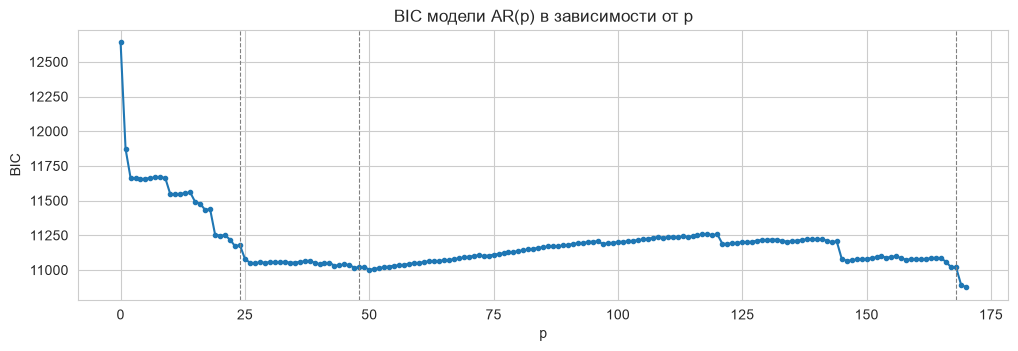

In [20]:
bic_by_p = pd.Series({len(k) if k else 0: v for k, v in ar_sel.bic.items()}).sort_index()

ax = bic_by_p.plot(marker=".", figsize=(12, 3.5), title="BIC модели AR(p) в зависимости от p")
for lag in (24, 48, 168):
    ax.axvline(lag, color="gray", ls="--", lw=0.8)
ax.set_xlabel("p"); ax.set_ylabel("BIC")
print(bic_by_p.loc[[1, 2, 24, 25, 48, 168, 170]].round(1))

BIC резко падает на первых лагах и ступенчато снижается до p=25, то есть до включения лага 24 (11178 -> 11081). Дальше до p около 50 кривая почти плоская, а на 50–120 растет. То есть новые лаги не несут информации, и штраф за параметры перевешивает

Следующие падения приходятся на p около 121 (5 суток), p 145 (6 суток) и p 168–170 (неделя), где BIC достигает минимума. Значит, недельная зависимость реальна, и AR с 170 лагами оправдана. Но 170 параметров оцениваются примерно по 500 наблюдениям (672 − 170), поэтому на тесте возможно переобучение

*ARIMA*

In [21]:
d_sub0, tbl0 = choose_d(sel)
print(f"d без сезонной разности: {d_sub0}")

d без сезонной разности: 0


In [22]:
display(tbl0)
g0 = grid_sarima(sel, d=d_sub0, p_range=range(4), q_range=range(4))
display(g0.head(5))
order_sub_plain = (int(g0.loc[0, "p"]), int(g0.loc[0, "d"]), int(g0.loc[0, "q"]))
res0 = SARIMAX(sel, order=order_sub_plain, trend="c" if d_sub0 == 0 else "n").fit(disp=False)
print("ARIMA", order_sub_plain)
print(acorr_ljungbox(res0.resid, lags=[24, 48]))

,d,ADF p-value,KPSS p-value
0,0,0.0364,0.1


,p,d,q,P,D,Q,AIC,BIC
0,3,0,3,0,0,0,15546.400297,15582.482364
1,2,0,2,0,0,0,15563.867335,15590.928885
2,3,0,2,0,0,0,15570.079819,15601.651627
3,2,0,1,0,0,0,15571.297002,15593.848294
4,3,0,1,0,0,0,15573.075776,15600.137327


ARIMA (3, 0, 3)
        lb_stat      lb_pvalue
24   676.493241  2.168131e-127
48  1055.213274  1.211458e-189


По тестам ADF и KPSS ряд стационарен без дифференцирования (ADF p=0.036, KPSS p=0.1), поэтому d = 0. По AIC выбрана ARIMA(3,0,3). Тест Льюнга–Бокса отвергает гипотезу о белом шуме в остатках. Следовательно, суточная зависимость целиком осталась в остатках, модель ее не описала

Это ожидаемо, так как прогноз ARIMA(3,0,3) опирается только на последние 3 часа и 3 ошибки, а до лага 24 не дотягивается. Значит, для этого ряда нужна сезонная модель

*SARIMA*

Сезонное дифференцирование D=1, d по ADF/KPSS после сезонной разности. Сетка $p, q \in \{0, 1, 2\}$, $P, Q \in \{0, 1\}$, критерий AIC. Недельный период m=168 в SARIMA не берем: число состояний в state-space форме становится 170 и подгонка на каждом окне занимает минуты

In [23]:
d_sub, tbl = choose_d(sel, seasonal_lag=24)
print(f"d после сезонной разности (m=24): {d_sub}")
display(tbl)

d после сезонной разности (m=24): 0


,d,ADF p-value,KPSS p-value
0,0,0.0001,0.1


In [24]:
%%time
g = grid_sarima(sel, d=d_sub, p_range=range(3), q_range=range(3),
                P_range=(0, 1), Q_range=(0, 1), D=1, m=24)
display(g.head(5))
r0 = g.loc[0]
order_sub = (int(r0.p), int(r0.d), int(r0.q))
sorder_sub = (int(r0.P), 1, int(r0.Q), 24)
res = SARIMAX(sel, order=order_sub, seasonal_order=sorder_sub).fit(disp=False)
print("SARIMA", order_sub, "x", sorder_sub)
print(acorr_ljungbox(res.resid[25:], lags=[24, 48]))

,p,d,q,P,D,Q,AIC,BIC
0,2,0,1,1,1,1,14127.670188,14154.513532
1,1,0,2,1,1,1,14128.487731,14155.331075
2,2,0,2,1,1,1,14129.279308,14160.596542
3,1,0,1,1,1,1,14133.924386,14156.293839
4,2,0,0,1,1,1,14144.516390,14166.885844


SARIMA (2, 0, 1) x (1, 1, 1, 24)
       lb_stat     lb_pvalue
24   99.256527  4.021682e-11
48  130.556741  1.447502e-09
CPU times: total: 48.9 s
Wall time: 45.3 s


После сезонной разности ряд стационарен (ADF p=0.0001, KPSS p=0.1), поэтому d=0. Во всех пяти лучших вариантах P = Q = 1, то есть суточная зависимость действительно нужна модели.

Статистика Льюнга–Бокса упала с 676 (обычная ARIMA) до 99, значит основную суточную структуру модель описала. Но белым шумом остатки все еще не являются, осталась недельная структура (будни/выходные), которую SARIMA с m = 24 не учитывает

*Хольт–Винтерс* 

сравниваем по AICc аддитивную/мультипликативную сезонность и периоды m=24 и m=168

In [25]:
hw_cfgs = []
for m in (24, 168):
    for seas in ("add", "mul"):
        for trend, damped in ((None, False), ("add", True)):
            hw_cfgs.append(dict(trend=trend, damped_trend=damped, seasonal=seas, seasonal_periods=m))
g_hw = grid_hw(sel, hw_cfgs)
display(g_hw.round(4))
best_hw = g_hw.iloc[0][["trend", "damped_trend", "seasonal", "seasonal_periods"]].to_dict()
best_hw["trend"] = None if pd.isna(best_hw["trend"]) else best_hw["trend"]
best_hw["damped_trend"] = bool(best_hw["damped_trend"]) and best_hw["trend"] is not None
best_hw["seasonal_periods"] = int(best_hw["seasonal_periods"])
print("Выбрано:", best_hw)

CFG[name] = dict(ar_lags=ar_sel.ar_lags,
                 order=order_sub_plain, seasonal_order=(0, 0, 0, 0),
                 arima_trend="c" if d_sub0 == 0 else "n",
                 sarima_order=order_sub, sarima_seasonal=sorder_sub,
                 hw=best_hw, hw_init="estimated", naive_m=24, naive_week_m=168)

,trend,damped_trend,seasonal,seasonal_periods,AICc,alpha,beta,gamma
0,NaN,False,mul,168,10911.6230,1.0,NaN,0.0
1,add,True,mul,168,10922.2355,1.0,0.0,0.0
2,NaN,False,add,168,11403.1439,1.0,NaN,0.0
3,add,True,add,168,11419.2905,1.0,0.0,0.0
4,NaN,False,mul,24,12400.5309,1.0,NaN,0.0
5,add,True,mul,24,12403.2355,1.0,0.0,0.0
6,NaN,False,add,24,13174.3635,1.0,NaN,0.0
7,add,True,add,24,13185.6928,1.0,0.0,0.0


Выбрано: {'trend': None, 'damped_trend': False, 'seasonal': 'mul', 'seasonal_periods': 168}


По AICc выбрана мультипликативная сезонность с периодом m = 168 без тренда. Недельный период лучше лучшего суточного варианта на 1490 единиц AICc, что подтверждает недельный цикл, видимый на ACF. Мультипликативная форма лучше аддитивной (на 490 единиц), так как амплитуда колебаний пропорциональна уровню ряда.

Тот же вариант с затухающим трендом хуже всего на 11 единиц: β=0.0, то есть тренда в нем фактически нет, а AICc штрафует за лишние параметры. Значит, тренд модели не нужен, а главное - правильный период: преимущество m=168 над m=24 огромно

При α=1.0 и γ=0.0 сезонный профиль не обновляется, а уровень полностью следует за последним наблюдением. По сути модель является копией прошлой недели с поправкой на текущий уровень. Поэтому в сравнение добавлен Naive-168.

## ЭКГ

In [26]:
name = "ECG"
x = SERIES[name]
o0 = test_origins(len(x), gap=GAP[name])[0]
sel = x[o0 - TRAIN_LEN[name]: o0]

In [27]:
# Период сердечного цикла — по R-пикам (как в лаб. работе 1)
peaks, _ = find_peaks(sel, distance=int(0.4 * FS), prominence=0.5 * (sel.max() - sel.min()))
rr = np.diff(peaks)
m_ecg = int(np.round(np.median(rr)))
print(f"R-пики: {peaks}; RR-интервалы: {rr}; медианный период m = {m_ecg} точек "
      f"({60 * FS / m_ecg:.0f} уд/мин)")

R-пики: [ 27 213 405 600 790 970]; RR-интервалы: [186 192 195 190 180]; медианный период m = 190 точек (79 уд/мин)


На окне подбора найдено 6 R-пиков, RR-интервалы 180–195 точек, медианный период m = 190 точек (79 уд/мин). Разброс интервалов около 15 точек (60 мс), что является естественной вариабельностью сердечного ритма

In [28]:
d_ecg, tbl = choose_d(sel)
print(f"d = {d_ecg}")

d = 0


In [29]:
tbl

,d,ADF p-value,KPSS p-value
0,0,0.0,0.1


ADF и KPSS согласованно указывают на стационарность. Сигнал колеблется вокруг постоянной изолинии без тренда, поэтому d = 0

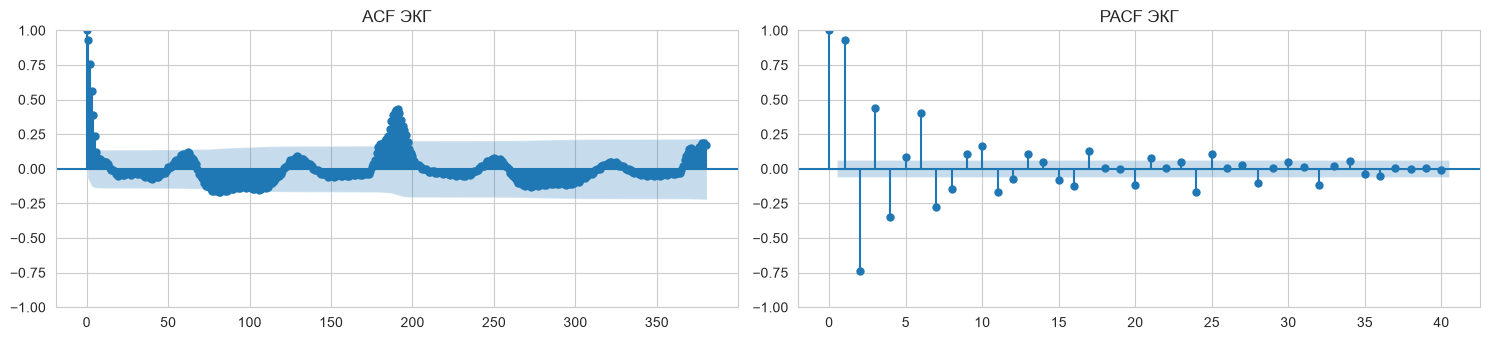

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.5))
plot_acf(sel, lags=2 * m_ecg, ax=axes[0], title="ACF ЭКГ")
plot_pacf(sel, lags=40, ax=axes[1], title="PACF ЭКГ", method="ywm")
plt.tight_layout()

ACF быстро затухает за первые 10 лагов. Главный пик ACF приходится на лаги 180–195 (около 0.43), то есть на один сердечный цикл, а слабый (около 0.18) где-то 380 (два цикла). Пики широкие: удары повторяются не строго через одно и то же число точек, периодичность есть, но размытая

PACF очень велика на лагах 1–7 и остается значимой на отдельных лагах до 25–30, а дальше в доверительной области. Локальную динамику сигнала описывает авторегрессия порядка 25, а сердечный цикл через PACF не виден. Короткая AR/ARIMA не сможет предсказать следующий удар

*AR*

максимальный лаг 40 (160 мс длительность комплекса QRS с запасом), выбор по BIC

In [31]:
ar_sel = ar_select_order(sel, maxlag=40, ic="bic", trend="c")
print("Лаги AR по BIC:", ar_sel.ar_lags)

Лаги AR по BIC: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25]


BIC выбрал AR(25) 100 мс истории. Это согласуется с PACF, где отдельные лаги значимы примерно до 25. 25 лагов покрывают длительность QRS-комплекса и волн, но до следующего удара модель не дотягивается, поэтому начало нового QRS она предсказать не сможет

*ARIMA* 

Сезонную SARIMA с m=190 не будем рассматривать, так как период плавает от удара к удару

In [32]:
g = grid_sarima(sel, d=d_ecg, p_range=range(5), q_range=range(4))
display(g.head(5))
order_ecg = (int(g.loc[0, "p"]), int(g.loc[0, "d"]), int(g.loc[0, "q"]))
res = SARIMAX(sel, order=order_ecg, trend="c" if d_ecg == 0 else "n").fit(disp=False)
print("ARIMA", order_ecg)
print(acorr_ljungbox(res.resid, lags=[10, 20]))

,p,d,q,P,D,Q,AIC,BIC
0,4,0,3,0,0,0,-1811.276941,-1767.107144
1,1,0,3,0,0,0,-1650.856676,-1621.410144
2,3,0,2,0,0,0,-1645.000252,-1610.645965
3,2,0,2,0,0,0,-1634.672516,-1605.225984
4,3,0,3,0,0,0,-1630.726564,-1591.464522


ARIMA (4, 0, 3)
       lb_stat     lb_pvalue
10  129.845732  5.022293e-23
20  172.544767  2.771243e-26


По AIC выбрана ARIMA(4,0,3) с заметным отрывом от остальных вариантов (160 единиц AIC). Значение p=4 лежит на границе сетки, так что при большей сетке AIC мог бы выбрать порядок выше

Тест Льюнга–Бокса отвергает белый шум в остатках (p = 10⁻²³ на лаге 10 и 10⁻²⁶ на лаге 20), то есть осталась структура. Скорее всего, это мелкие высокочастотные колебания на изолинии с периодом где-то 4 отсчета (вероятно, сетевая наводка 60 Гц: запись американская, 250/60 ≈ 4.2) и быстрые фронты QRS, которые модель низкого порядка описывает неполностью

*Хольт–Винтерс*

сравниваем по AICc вариант без сезонности (метод Хольта/SES) и аддитивную и мультипликативную сезонность с m = медианный RR. Инициализация heuristic: при m = 190 «estimated» пытается оценить 190 начальных сезонных коэффициентов всего по 5 периодам

In [33]:
hw_cfgs = [
    dict(trend=None, seasonal=None),
    dict(trend="add", damped_trend=True, seasonal=None),
    dict(trend=None, seasonal="add", seasonal_periods=m_ecg),
]
if sel.min() > 0:   # мультипликативная сезонность допустима только для положительного ряда
    hw_cfgs.append(dict(trend=None, seasonal="mul", seasonal_periods=m_ecg))
g_hw = grid_hw(sel, hw_cfgs, init="heuristic")
display(g_hw.round(4))
best_hw = {k: v for k, v in g_hw.iloc[0].items()
           if k in ("trend", "damped_trend", "seasonal", "seasonal_periods") and not pd.isna(v)}
if "seasonal_periods" in best_hw:
    best_hw["seasonal_periods"] = int(best_hw["seasonal_periods"])
print("Выбрано:", best_hw)

CFG[name] = dict(ar_lags=ar_sel.ar_lags, order=order_ecg, seasonal_order=(0, 0, 0, 0), sarima_order=None,
                 arima_trend="c" if d_ecg == 0 else "n",
                 hw=best_hw, hw_init="heuristic", naive_m=m_ecg)

,trend,seasonal,AICc,alpha,beta,gamma,damped_trend,seasonal_periods
0,add,NaN,-3767.4454,1.0,1.0,NaN,True,NaN
1,NaN,NaN,-3186.7453,1.0,NaN,NaN,NaN,NaN
2,NaN,mul,-2762.1355,1.0,NaN,0.0,NaN,190.0
3,NaN,add,-2730.7137,1.0,NaN,0.0,NaN,190.0


Выбрано: {'trend': 'add', 'damped_trend': True}


По AICc выбран метод Хольта с затухающим трендом, без сезонности. Он лучше SES на 580 единиц и лучше сезонных вариантов на 1000–1040. При этом α = β = 1: уровень и наклон полностью определяются последними наблюдениями, то есть модель фактически продлевает последний наклон сигнала с затуханием. Это хорошо описывает гладкий сигнал на один шаг вперед, но на 7–14 шагов на крутых фронтах QRS прогноз будет улетать в сторону последнего наклона. AICc оценивает качество подгонки на один шаг, а не дальний прогноз, поэтому посмотрим, как модель поведет себя на тесте

# Тестирование 

Для каждого блока модель обучается один раз и строит прогноз на 14 шагов; ошибки на горизонтах 1 и 7 считаются по первым 1 и 7 точкам этого прогноза

In [34]:
%%time
rows, forecasts = [], {}
for name, x in SERIES.items():
    cfg = CFG[name]
    for k, o in enumerate(test_origins(len(x), gap=GAP[name])):
        train = x[o - TRAIN_LEN[name]: o]
        test = x[o: o + H_MAX]
        for mname, f in MODELS.items():
            if mname == "SARIMA" and cfg.get("sarima_order") is None:
                continue
            if mname == "Naive-168" and "naive_week_m" not in cfg:
                continue
            yhat = np.asarray(f(train, cfg), dtype=float)
            forecasts[(name, mname, k)] = yhat
            for h in HORIZONS:
                rows.append(dict(series=name, model=mname, horizon=h, segment=k,
                                 MAPE=mape(test[:h], yhat[:h]), MAE=mae(test[:h], yhat[:h])))
results = pd.DataFrame(rows)
results.head()

CPU times: total: 36.9 s
Wall time: 35.7 s


,series,model,horizon,segment,MAPE,MAE
0,Apple,AR,1,0,0.134255,0.304331
1,Apple,AR,7,0,1.094249,2.450111
2,Apple,AR,14,0,1.785097,3.961783
3,Apple,ARIMA,1,0,0.149659,0.339249
4,Apple,ARIMA,7,0,1.084615,2.430363


# Сводная таблица

Медиана и среднее MAPE (%) по 10 блокам. Медиана устойчивее к единичным выбросам (важно для ЭКГ и ночных часов метро)

In [35]:
summary = (results.groupby(["series", "horizon", "model"])["MAPE"]
           .agg(median="median", mean="mean", std="std").round(2))
table = summary["median"].unstack("model").reindex(columns=list(MODELS))
display(table.style.format("{:.2f}", na_rep="—").highlight_min(axis=1, color="#c6efce")
        .set_caption("Медиана MAPE, % (зеленым — лучшая модель)"))

In [36]:
mean_table = summary["mean"].unstack("model").reindex(columns=list(MODELS))
display(mean_table.style.format("{:.2f}", na_rep="—").highlight_min(axis=1, color="#c6efce")
        .set_caption("Среднее MAPE, % (зеленым — лучшая модель)"))

**Apple** Все модели дают практически одинаковую ошибку 0.45% на 1 шаг, 1.38% на 7 и 2.8% на 14. ARIMA(0,1,0), SES с α=1 и наивный прогноз математически совпадают, а AR(1) с φ₁ ≈ 0.998 почти не отличается от них. Предсказуемой структуры в цене нет

**Метро** Лучшие — копия прошлой недели (Naive-168) и Хольт–Винтерс (m=168): медиана 1.2 / 2.5 / 3.6% против 1.7 / 3.2 / 3.5% на горизонтах 1 / 7 / 14 соответтственно. На 1 и 7 шагах точнее Naive-168, на 14 шагах они практически равны. Ошибка у обоих почти не растет с горизонтом, потому что недельный профиль задает форму прогноза на любое число шагов

Третья AR(170) (1.7 / 8.2 / 12.8%): лаг 168 позволяет ей учесть недельный цикл, но из-за 170 параметров ошибка быстро растет с горизонтом. SARIMA (6.2 / 14.2 / 25.8%) и сезонно-наивный m=24 (13.6 / 19.2 / 20.8%) заметно хуже: они переносят профиль будних дней на выходные и наоборот. Обычная ARIMA непригодна (32% и 206% на 7 и 14 шагов), она не видит суточного цикла

**ЭКГ** На 1 шаг лучше всех AR - соседние отсчеты почти совпадают, и авторегрессия точна. На 7 и 14 шагов вывод зависит от статистики. По медиане лучший наивный прогноз «как один удар назад» (1.29% и 1.32%), чуть хуже ARIMA (1.42%) и AR (1.69%). По среднему лучшая AR (1.56% и 2.38%), а у наивного прогноза 3.37% и 3.09%: в большинстве блоков он точен, но в отдельных, где копия удара сдвинута по фазе, ошибается сильнее всех. Хольт–Винтерс — худший на 7 и 14 шагах и по медиане (3.3% и 4.2%), и по среднему (3.1% и 5.1%)

In [37]:
display(summary.unstack("model").round(2))

median                                                mean  \
model              AR   ARIMA Holt-Winters  Naive Naive-168 SARIMA     AR   
series horizon                                                              
Apple  1         0.46    0.45         0.45   0.45       NaN    NaN   1.10   
       7         1.36    1.38         1.38   1.38       NaN    NaN   1.93   
       14        2.83    2.77         2.77   2.77       NaN    NaN   3.15   
ECG    1         0.36    0.53         1.12   1.37       NaN    NaN   0.47   
       7         1.57    1.42         3.27   1.29       NaN    NaN   1.56   
       14        1.69    2.35         4.20   1.32       NaN    NaN   2.38   
Subway 1         1.65   12.84         1.71  13.56      1.15   6.17  30.22   
       7         8.17   32.45         3.19  19.24      2.52  14.16  21.79   
       14       12.80  205.65         3.49  20.79      3.60  25.84  21.70   

                                                               std          \
model            ARIMA Holt-Winters  Naive Naive-168 SARIMA     AR   ARIMA   
series horizon                                                               
Apple  1          1.11         1.11   1.11       NaN    NaN   1.37    1.38   
       7          1.94         1.94   1.94       NaN    NaN   1.26    1.28   
       14         3.16         3.16   3.16       NaN    NaN   1.33    1.38   
ECG    1          0.67         1.06   5.77       NaN    NaN   0.40    0.30   
       7          1.74         3.14   3.37       NaN    NaN   0.56    1.20   
       14         2.79         5.12   3.09       NaN    NaN   2.08    2.10   
Subway 1         94.05         2.39  68.44      1.75  13.51  67.67  180.53   
       7        150.19         5.22  31.89      4.22  21.39  43.03  220.47   
       14       235.21         4.73  33.48      3.97  31.66  23.03  203.09   

                                                      
model          Holt-Winters   Naive Naive-168 SARIMA  
series horizon                                        
Apple  1               1.38    1.38       NaN    NaN  
       7               1.28    1.28       NaN    NaN  
       14              1.38    1.38       NaN    NaN  
ECG    1               0.48   13.10       NaN    NaN  
       7               1.13    5.28       NaN    NaN  
       14              3.13    3.41       NaN    NaN  
Subway 1               2.00  120.58      1.62  24.26  
       7               4.48   40.39      4.41  22.83  
       14              3.28   29.33      2.59  24.08

In [38]:
mae_table = results.groupby(["series", "horizon", "model"])["MAE"].median().unstack("model").reindex(columns=list(MODELS))
display(mae_table.style.format("{:.4g}", na_rep="—").highlight_min(axis=1, color="#c6efce")
        .set_caption("Медиана MAE (в единицах ряда)"))

По MAE выводы в целом совпадают с медианой MAPE. В метро по MAE Naive-168 лучше Хольта–Винтерса на всех горизонтах: 742 / 2478 / 1948 пассажиров против 793 / 3028 / 2278, разница 7–22%. По медиане MAPE Хольт–Винтерс впереди только на 14 шагах (3.5 против 3.6%), то есть копия прошлой недели как минимум не хуже. В ЭКГ по MAE на 7 и 14 шагах тоже лучший наивный прогноз. Для Apple лучшая модель в таблице выбрана из практически равных значений, разница в сотых долях процента случайна

# Boxplot mape

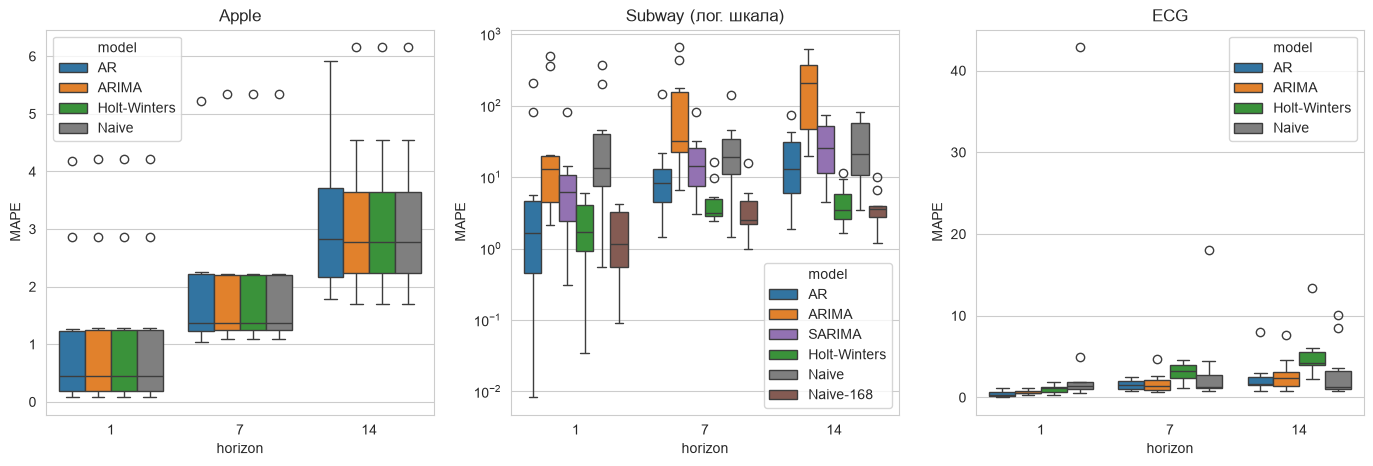

In [39]:
box_colors = dict(zip(MODELS, ["tab:blue", "tab:orange", "tab:purple", "tab:green", "tab:gray", "tab:brown"]))
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, name in zip(axes, SERIES):
    d = results[results.series == name]
    order = [m for m in MODELS if m in d.model.unique()]
    sns.boxplot(data=d, x="horizon", y="MAPE", hue="model", hue_order=order,
                palette=box_colors, ax=ax, showfliers=True)
    ax.set_title(name)
    if name == "Subway":
        ax.set_yscale("log"); ax.set_title("Subway (лог. шкала)")

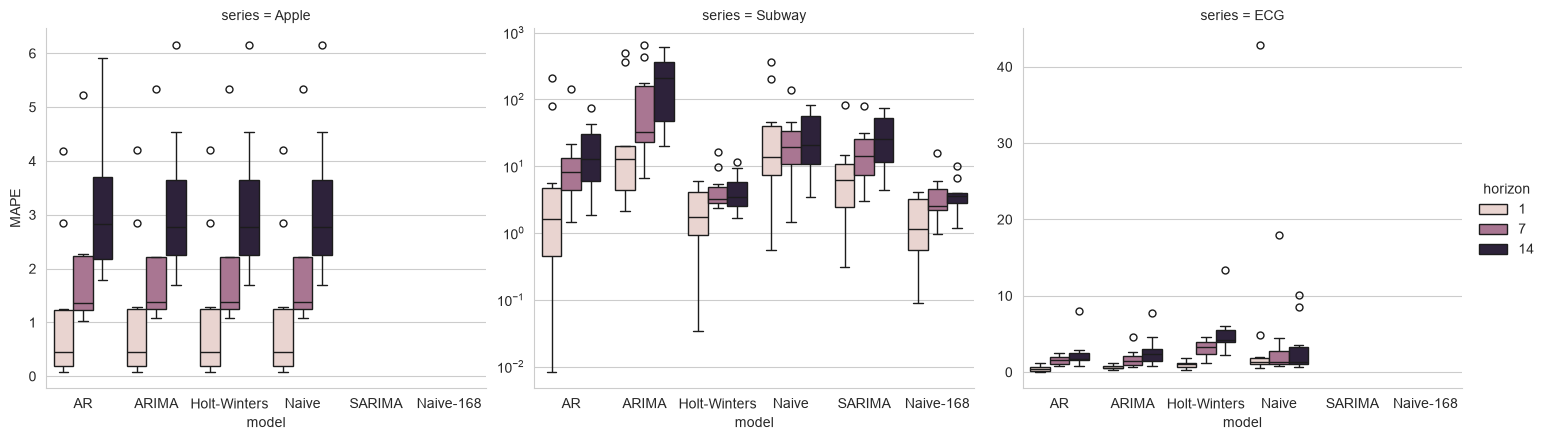

In [40]:
g = sns.catplot(data=results, x="model", y="MAPE", hue="horizon", col="series",
                kind="box", sharey=False, height=4.5, aspect=1.1)
g.axes.flat[1].set_yscale("log")

Высота ящиков у Apple почти одинакова для всех моделей, а разброс между блоками намного больше разницы между моделями.

У метро у ARIMA огромный разброс (от единиц до сотен процентов). У Хольта–Винтерса и Naive-168 ящики самые низкие и узкие на всех горизонтах, то есть обе модели стабильнее. У AR на 1 шаг медиана низкая, но разброс огромный (от 0.01% до 200%): в отдельных блоках, вероятно в ночные часы с малым пассажиропотоком, процентная ошибка резко растет.

У ЭКГ ящики Хольта–Винтерса самые высокие на горизонтах 7 и 14. У наивного прогноза медиана низкая, но есть сильные выбросы (43% на 1 шаг, 18% на 7): он либо очень точен, либо сильно ошибается

Для ЭКГ посмотрим ошибку по каждому блоку отдельно, чтобы увидеть, в каких блоках находится QRS-комплекс и насколько он портит статистику

In [41]:
ecg_blocks = (results[(results.series == "ECG") & (results.horizon == 14)]
              .pivot(index="segment", columns="model", values="MAPE").reindex(columns=list(MODELS)).dropna(axis=1, how="all"))
origins_ecg = test_origins(len(SERIES["ECG"]), gap=GAP["ECG"])
ecg_blocks.index = [f"{k}: точки {o}–{o + H_MAX - 1}" for k, o in enumerate(origins_ecg)]
display(ecg_blocks.style.format("{:.2f}").background_gradient(axis=None, cmap="Reds")
        .set_caption("ЭКГ: MAPE, % на горизонте 14 по блокам"))

model,AR,ARIMA,Holt-Winters,Naive
0: точки 1186–1199,1.00,0.75,5.06,1.29
1: точки 1586–1599,1.61,4.63,4.06,3.61
2: точки 1986–1999,1.77,1.29,2.20,2.25
3: точки 2386–2399,1.70,1.92,3.90,0.73
4: точки 2786–2799,2.96,3.07,2.65,0.80
5: точки 3186–3199,1.56,1.88,4.34,1.28
6: точки 3586–3599,0.79,0.76,6.01,0.95
7: точки 3986–3999,7.97,7.70,13.36,8.53
8: точки 4386–4399,2.82,3.10,5.65,10.10
9: точки 4786–4799,1.67,2.78,3.95,1.34


In [42]:
r_all, _ = find_peaks(ecg, distance=int(0.4 * FS), prominence=0.5 * (ecg.max() - ecg.min()))
for k, o in enumerate(origins_ecg):
    inside = [int(p) for p in r_all if o <= p < o + H_MAX]
    print(f"блок {k}: точки {o}–{o + H_MAX - 1}", "R-пик в", inside if inside else "—")

блок 0: точки 1186–1199 R-пик в —
блок 1: точки 1586–1599 R-пик в —
блок 2: точки 1986–1999 R-пик в —
блок 3: точки 2386–2399 R-пик в —
блок 4: точки 2786–2799 R-пик в —
блок 5: точки 3186–3199 R-пик в —
блок 6: точки 3586–3599 R-пик в —
блок 7: точки 3986–3999 R-пик в [3999]
блок 8: точки 4386–4399 R-пик в —
блок 9: точки 4786–4799 R-пик в —


Проверка показывает, что R-пик попадает только в блок 7, на его последнюю точку (3999), то есть блок захватывает весь подъем QRS. Здесь ошибаются все модели (7.7–13.4%). Начало QRS не предсказывает ни одна из них. В блоке 8 R-пика нет, но наивный прогноз ошибается сильнее остальных, из-за вариабельности ритма прошлый удар скопирован со сдвигом по фазе, и модель рисует пик там, где его нет. Вне R-пика наивный прогноз один из лучших (блоки 0, 3-6, 9)

Хольт–Винтерс худший в шести блоках из 10 (0, 3, 5, 6, 7, 9)

# Примеры прогнозов

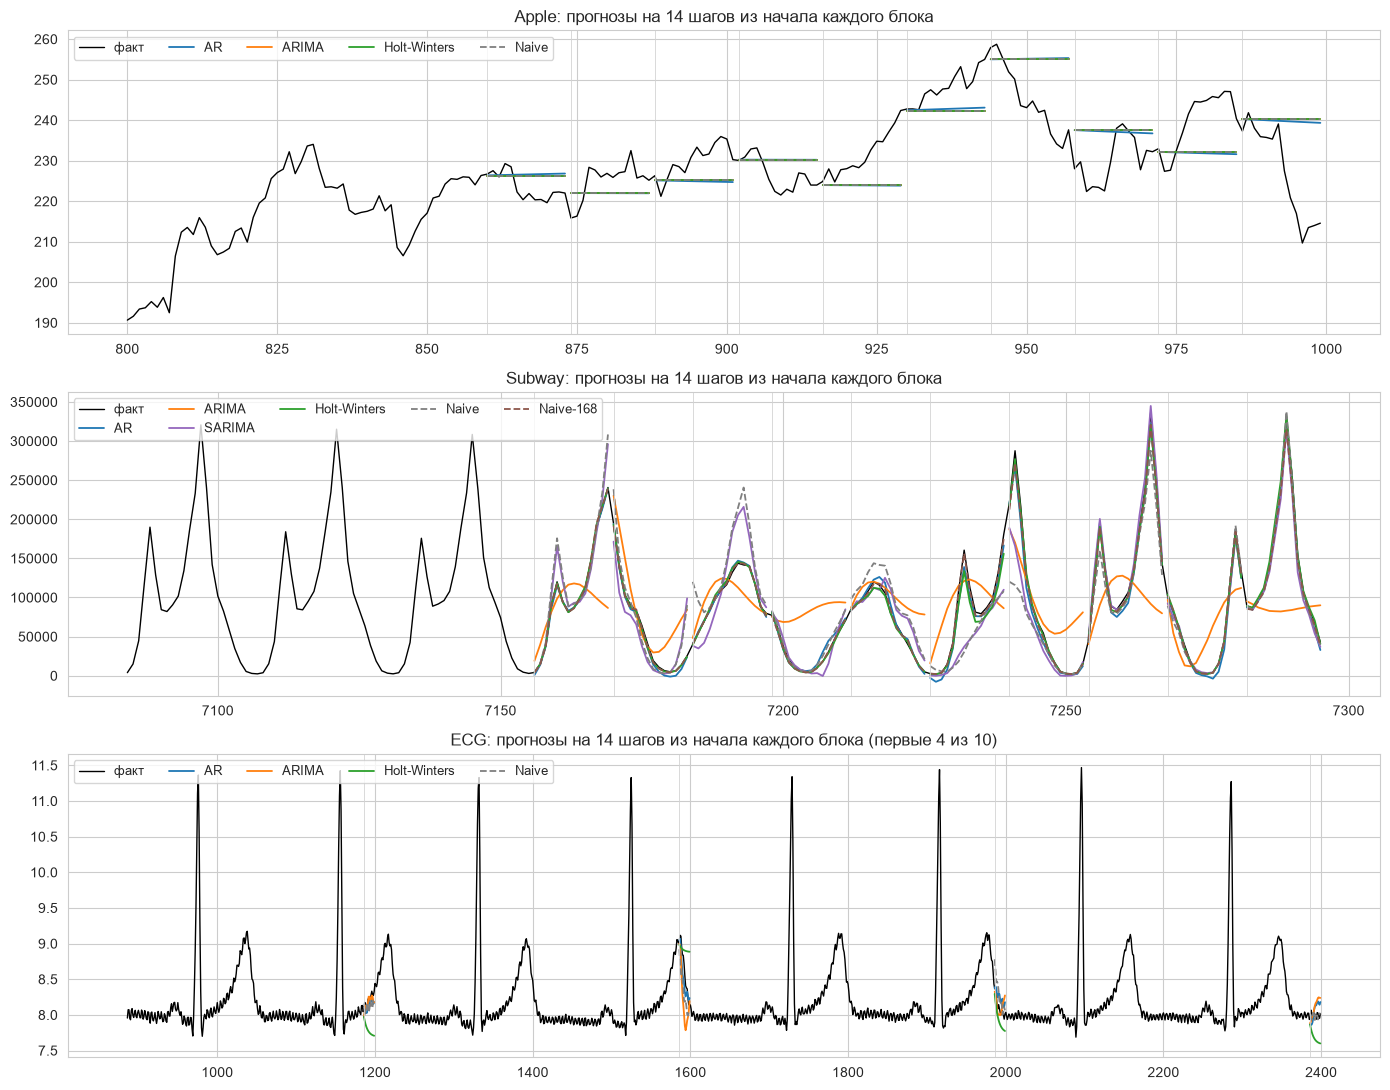

In [43]:
fig, axes = plt.subplots(3, 1, figsize=(14, 11))
colors = dict(zip(MODELS, ["tab:blue", "tab:orange", "tab:purple", "tab:green", "tab:gray", "tab:brown"]))
for ax, (name, x) in zip(axes, SERIES.items()):
    origins = test_origins(len(x), gap=GAP[name])
    ctx = {"Apple": 60, "Subway": 24 * 3, "ECG": 300}[name]
    shown = origins[:4] if name == "ECG" else origins
    end = shown[-1] + H_MAX
    ax.plot(np.arange(origins[0] - ctx, end), x[origins[0] - ctx: end], color="black", lw=1, label="факт")
    for k, o in enumerate(shown):
        for mname in MODELS:
            if (name, mname, k) not in forecasts:
                continue
            ax.plot(np.arange(o, o + H_MAX), forecasts[(name, mname, k)], color=colors[mname],
                    lw=1.3, ls="--" if mname.startswith("Naive") else "-", label=mname if k == 0 else None)
        ax.axvline(o, color="lightgray", lw=0.6)
    ax.set_title(f"{name}: прогнозы на 14 шагов из начала каждого блока"
                 + (" (первые 4 из 10)" if name == "ECG" else ""))
    ax.legend(ncol=5, fontsize=9)
plt.tight_layout()

**Метро** Тестовая зона начинается в пятницу в 04:00 и содержит два перехода. Первый «будни -> выходные»: в субботу SARIMA и сезонно-наивный прогноз (m=24) переносят пятничный профиль с высокими пиками и завышают прогноз примерно в 1.5 раза. Второй «выходные -> будни»: в понедельник они переносят воскресный профиль и сильно занижают вечерний пик. Хольт–Винтерс и Naive-168 знают недельный профиль и почти совпадают с фактом в оба перехода. Обычная ARIMA рисует плавную синусоиду, не совпадающую с реальным профилем

**ЭКГ** (первые 4 блока, R-пик в них не попадает) Хорошо видно, что Хольт–Винтерс продлевает последний наклон: в блоках 0 и 3 уходит вниз ниже изолинии, а в блоке 1 на спаде зубца T остается на уровне 8.9, пока сигнал опускается к 8.0. ARIMA в блоке 1 тоже ошибается, переоценивая спад

In [44]:
best = pd.DataFrame({
    "лучшая по медиане MAPE": table.idxmin(axis=1),
    "лучшая по среднему MAPE": mean_table.idxmin(axis=1),
    "лучшая по MAE": mae_table.idxmin(axis=1),
})
best

лучшая по медиане MAPE лучшая по среднему MAPE лучшая по MAE
series horizon                                                             
Apple  1                        ARIMA                      AR  Holt-Winters
       7                           AR                      AR            AR
       14                       ARIMA                      AR            AR
ECG    1                           AR                      AR            AR
       7                        Naive                      AR         Naive
       14                       Naive                      AR         Naive
Subway 1                    Naive-168               Naive-168     Naive-168
       7                    Naive-168               Naive-168     Naive-168
       14                Holt-Winters               Naive-168     Naive-168

# Итоги

1. Качество прогноза определяется структурой ряда, а не сложностью модели. Для ряда без предсказуемой структуры (Apple) все модели сводятся к случайному блужданию и не превосходят наивный прогноз
2. Для ряда со стабильной сезонностью (метро) решающее значение имеет учет правильного периода. Хольт–Винтерс с недельным периодом и копия прошлой недели (Naive-168) лучшие на всех горизонтах (1–4% MAPE), причем копия прошлой недели не хуже, а на 1–7 шагах точнее: сложная модель ничего не добавляет к правильному периоду. AR(170), где есть лаг 168, - третья. Модели с суточным периодом (SARIMA, сезонно-наивный m=24) ошибаются на переходах будни выходные (14–26% на 7–14 шагах), несезонная ARIMA непригодна
3. Для квазипериодического сигнала (ЭКГ) классические модели хороши только на 1 шаг. Лучшая на 1 шаг AR(25). На 7–14 шагов по медиане лучший наивный прогноз (копия прошлого удара), а по среднему — AR: наивный прогноз в большинстве блоков точен, но из-за плавающего периода копия прошлого удара иногда ставит R-пик туда, где его нет, и тогда ошибка самая большая. Если важна надежность, а не типичный случай, предпочтительнее AR. Предсказать начало QRS-комплекса не может ни одна из моделей
4. Ошибка в целом растет с горизонтом. Медленнее всего у моделей с правильным сезонным периодом (Хольт–Винтерс и Naive-168 для метро). Исключение - это наивный прогноз для ЭКГ, его медиана почти не меняется (1.37, 1.29, 1.32%), так как ошибка копии удара зависит от фазы цикла, а не от номера шага. Его среднее даже падает (5.8, 3.4, 3.1%). В одном блоке скопированный R-пик пришелся точно на первую точку, и ошибка на горизонте 1 составила 43%
5. Выбор гиперпараметров по информационным критериям оценивает качество подгонки на один шаг и не гарантирует лучшего дальнего прогноза. Например, Хольт с затухающим трендом для ЭКГ: по AICc он лучший с большим отрывом, но на 7–14 шагах худший из всех моделей и по медиане, и по среднему, потому что продлевает последний наклон сигнала. Поэтому информационные критерии использовались только для выбора конфигурации внутри каждой модели, а сравнивались модели между собой по ошибке на тестовых блоках

**Ограничения**
1. В ЭКГ 10 блоков разнесены на 2.1 удара и покрывают разные фазы кардиоцикла, но взяты из одной 19-секундной записи одного человека. R-пик попал только в один блок (7), причем на его последнюю точку, поэтому оценка поведения моделей на QRS держится на единственном случае.
2. Тестовая зона метро (140 ч) покрывает пятницу–среду: два перехода «будни -> выходные» и «выходные -> будни», но это одна неделя без праздников. На неделях с праздниками недельные модели будут ошибаться
3. AR(170) для метро: 170 лежит на границе перебора, поэтому истинный минимум BIC может быть дальше